# AIOps – Cloud Infrastructure Anomaly Detection

## Phase 2: Exploratory Data Analysis & Infrastructure Metrics Investigation

### 1. Project Introduction
Modern cloud computing environments generate continuous streams of high-frequency telemetry across compute, memory, disk, and network interfaces. When failures occur—such as memory leaks, runaway compute threads, cascading microservice delays, or network traffic surges—traditional static threshold monitoring often results in alert fatigue or fails to capture subtle multi-metric anomalies.

This AIOps project employs unsupervised Machine Learning (**Isolation Forest**) to model normal system baselines and uncover abnormal behavior automatically without requiring labeled training datasets. In Phase 2, we explore the synthetic telemetry dataset modeling realistic AWS EC2 server metrics across normal operation and various real-world failure modes.

### 2. Dataset Description
The dataset consists of **10,000 sequential one-minute observations** (~6.94 days of continuous infrastructure operations) for simulated compute instance `i-0f8b3c4a2d1e98765`.

The features capture:
- `timestamp`: Observation timestamp (1-minute intervals).
- `instance_id`: Cloud compute instance identifier.
- `cpu_usage`: Percentage CPU utilization (0.0% – 100.0%).
- `memory_usage`: Percentage RAM occupancy (0.0% – 100.0%).
- `disk_usage`: Percentage storage volume occupancy (0.0% – 100.0%).
- `network_in`: Inbound network throughput in Megabits per second (Mbps).
- `network_out`: Outbound network throughput in Megabits per second (Mbps).
- `request_count`: Total incoming application requests per minute.
- `response_time`: Application latency in milliseconds (ms).
- `anomaly_label`: Ground-truth indicator (0 = Normal, 1 = Anomaly).
- `anomaly_type`: Category of behavior (`normal`, `cpu_spike`, `memory_spike`, `disk_anomaly`, `network_spike`, `combined_anomaly`, `gradual_degradation`).

### 3. Import Required Libraries

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root can be imported for centralized configurations
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import config

# Configure aesthetic styling
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["figure.dpi"] = 120

print(f"Pandas version   : {pd.__version__}")
print(f"NumPy version    : {np.__version__}")
print(f"Project root     : {config.PROJECT_ROOT}")

C:\Users\vineg\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\vineg\AppData\Local\Temp\matplotlib-fv7wqzcd because there was an issue with the default path (C:\Users\vineg\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Pandas version   : 3.0.6
NumPy version    : 1.26.4
Project root     : C:\Apps\Monitoring_System\AIOps-Cloud-Infrastructure-Anomaly-Detection


### 4. Load infrastructure_metrics.csv

In [2]:
data_path = config.RAW_DATA_FILE
df = pd.read_csv(data_path)
df["timestamp"] = pd.to_datetime(df["timestamp"])
print(f"Successfully loaded dataset from: {data_path}")

Successfully loaded dataset from: C:\Apps\Monitoring_System\AIOps-Cloud-Infrastructure-Anomaly-Detection\data\raw\infrastructure_metrics.csv


### 5. Display the First 10 Records

In [3]:
df.head(10)

,timestamp,instance_id,cpu_usage,memory_usage,disk_usage,network_in,network_out,request_count,response_time,anomaly_label,anomaly_type
0,2026-03-01 00:00:00,i-0f8b3c4a2d1e98765,25.01,46.00,41.56,25.87,54.85,179,40.16,0,normal
1,2026-03-01 00:01:00,i-0f8b3c4a2d1e98765,26.34,45.57,41.35,25.80,60.77,154,37.38,0,normal
2,2026-03-01 00:02:00,i-0f8b3c4a2d1e98765,24.46,45.70,41.48,22.27,61.18,186,37.66,0,normal
3,2026-03-01 00:03:00,i-0f8b3c4a2d1e98765,26.39,45.76,41.41,25.46,60.64,189,40.80,0,normal
4,2026-03-01 00:04:00,i-0f8b3c4a2d1e98765,24.85,45.00,41.73,24.35,52.81,137,50.70,0,normal
5,2026-03-01 00:05:00,i-0f8b3c4a2d1e98765,25.01,44.56,41.42,23.34,59.65,149,39.12,0,normal
6,2026-03-01 00:06:00,i-0f8b3c4a2d1e98765,29.61,44.66,41.38,28.72,64.56,174,38.61,0,normal
7,2026-03-01 00:07:00,i-0f8b3c4a2d1e98765,25.06,44.65,41.28,20.51,56.89,166,36.39,0,normal
8,2026-03-01 00:08:00,i-0f8b3c4a2d1e98765,20.49,44.53,41.42,20.60,53.72,171,38.27,0,normal
9,2026-03-01 00:09:00,i-0f8b3c4a2d1e98765,21.86,44.76,41.52,25.62,53.21,156,40.07,0,normal


### 6. Display Dataset Dimensions

In [4]:
rows, cols = df.shape
print(f"Dataset Dimensions: {rows:,} rows x {cols} columns")

Dataset Dimensions: 10,000 rows x 11 columns


### 7. Display Column Data Types

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp      10000 non-null  datetime64[us]
 1   instance_id    10000 non-null  str           
 2   cpu_usage      10000 non-null  float64       
 3   memory_usage   10000 non-null  float64       
 4   disk_usage     10000 non-null  float64       
 5   network_in     10000 non-null  float64       
 6   network_out    10000 non-null  float64       
 7   request_count  10000 non-null  int64         
 8   response_time  10000 non-null  float64       
 9   anomaly_label  10000 non-null  int64         
 10  anomaly_type   10000 non-null  str           
dtypes: datetime64[us](1), float64(6), int64(2), str(2)
memory usage: 859.5 KB


### 8. Check Missing Values

In [6]:
missing_summary = df.isna().sum()
print("Missing values per column:")
print(missing_summary)
assert missing_summary.sum() == 0, "Unexpected null values detected!"

Missing values per column:
timestamp        0
instance_id      0
cpu_usage        0
memory_usage     0
disk_usage       0
network_in       0
network_out      0
request_count    0
response_time    0
anomaly_label    0
anomaly_type     0
dtype: int64


### 9. Check Duplicate Timestamps

In [7]:
duplicate_count = df["timestamp"].duplicated().sum()
is_monotonic = df["timestamp"].is_monotonic_increasing
print(f"Duplicate timestamps: {duplicate_count}")
print(f"Strictly monotonic increasing: {is_monotonic}")

Duplicate timestamps: 0
Strictly monotonic increasing: True


### 10. Statistical Summary

In [8]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,10000,2026-03-04 11:19:30,2026-03-01 00:00:00,2026-03-02 17:39:45,2026-03-04 11:19:30,2026-03-06 04:59:15,2026-03-07 22:39:00,NaN
cpu_usage,10000.0,35.06118,15.54,29.15,33.58,38.32,99.7,10.824497
memory_usage,10000.0,47.696575,37.02,43.9975,46.61,49.23,99.14,7.627725
disk_usage,10000.0,45.549905,41.28,43.34,45.18,47.0,99.49,5.001145
network_in,10000.0,42.117293,15.59,27.25,33.15,39.34,879.42,72.580646
network_out,10000.0,94.06444,40.5,65.68,81.56,97.6825,1376.69,104.047394
request_count,10000.0,308.0864,112.0,199.0,282.0,364.0,2893.0,233.656844
response_time,10000.0,66.803413,33.47,41.3275,45.35,49.18,2394.85,159.014413
anomaly_label,10000.0,0.05,0.0,0.0,0.0,0.0,1.0,0.217956


### 11. Anomaly Distribution

                     Record Count  Percentage (%)
anomaly_type                                     
normal                       9500           95.00
gradual_degradation           100            1.00
combined_anomaly               85            0.85
cpu_spike                      80            0.80
memory_spike                   80            0.80
disk_anomaly                   80            0.80
network_spike                  75            0.75


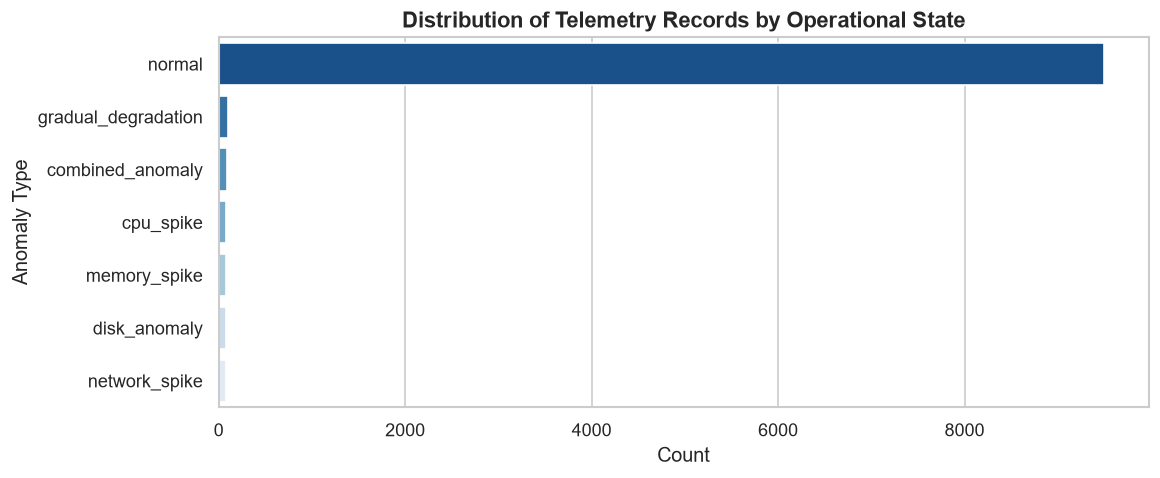

In [9]:
total = len(df)
counts = df["anomaly_type"].value_counts()
summary_df = pd.DataFrame({
    "Record Count": counts,
    "Percentage (%)": (counts / total * 100).round(2)
})
print(summary_df)

plt.figure(figsize=(10, 4))
palette = sns.color_palette("Blues_r", n_colors=len(counts))
sns.barplot(x=counts.values, y=counts.index, palette=palette, hue=counts.index, legend=False)
plt.title("Distribution of Telemetry Records by Operational State", fontsize=13, fontweight="bold")
plt.xlabel("Count")
plt.ylabel("Anomaly Type")
plt.show()

### 12. CPU Utilization Visualization

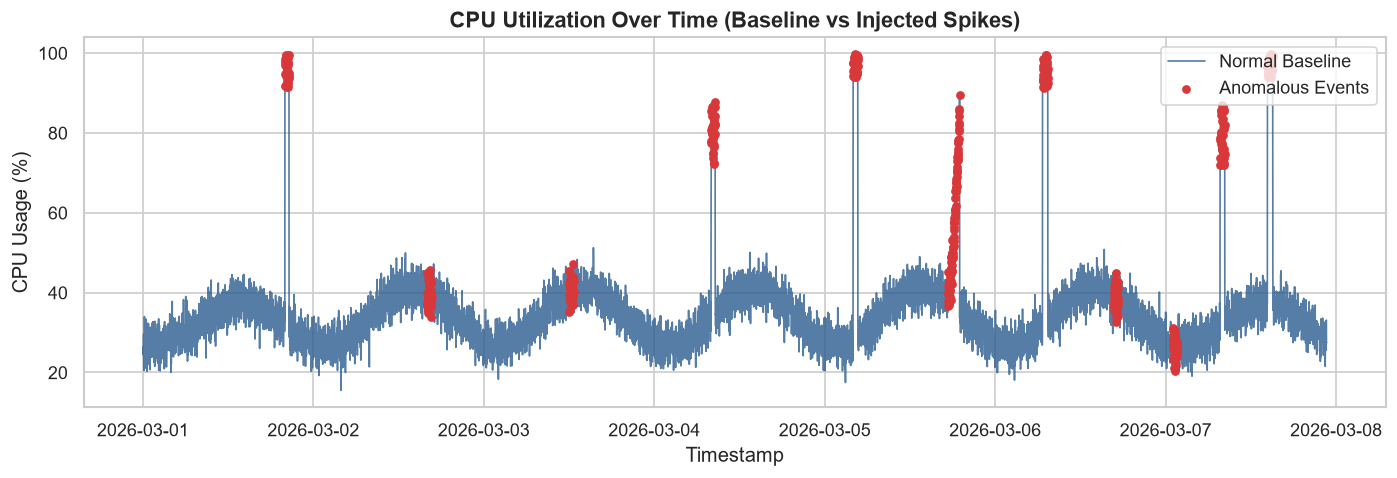

In [10]:
plt.figure(figsize=(14, 4))
plt.plot(df["timestamp"], df["cpu_usage"], color="#2b5c8f", label="Normal Baseline", linewidth=1.0, alpha=0.8)
anom = df[df["anomaly_label"] == 1]
plt.scatter(anom["timestamp"], anom["cpu_usage"], color="#d9383a", s=18, label="Anomalous Events", zorder=5)
plt.title("CPU Utilization Over Time (Baseline vs Injected Spikes)", fontsize=13, fontweight="bold")
plt.xlabel("Timestamp")
plt.ylabel("CPU Usage (%)")
plt.legend(loc="upper right")
plt.show()

### 13. Memory Utilization Visualization

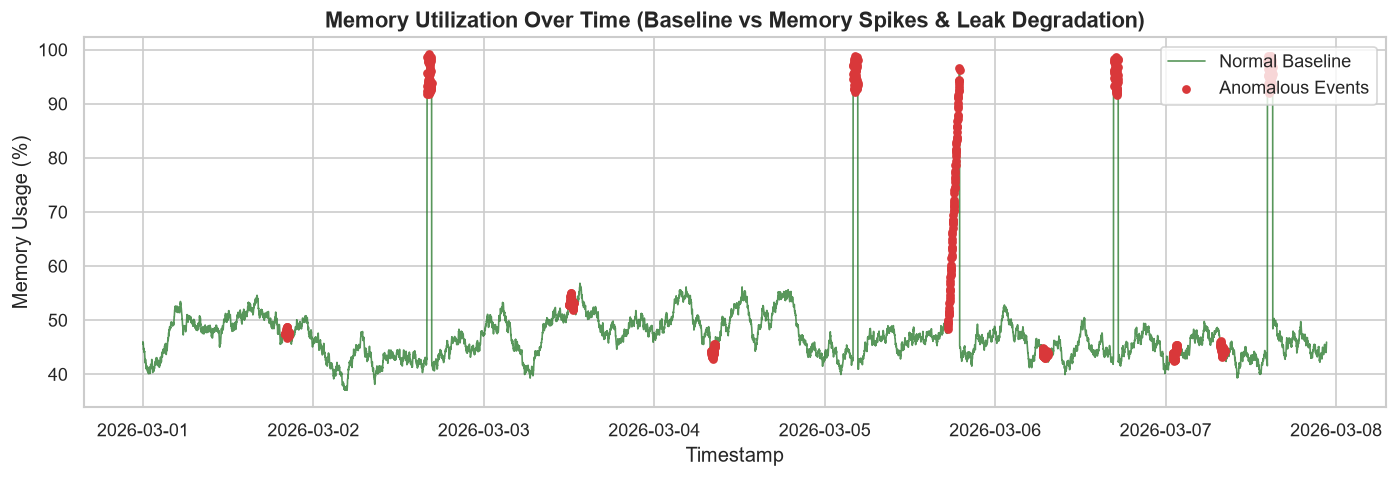

In [11]:
plt.figure(figsize=(14, 4))
plt.plot(df["timestamp"], df["memory_usage"], color="#2e7d32", label="Normal Baseline", linewidth=1.0, alpha=0.8)
plt.scatter(anom["timestamp"], anom["memory_usage"], color="#d9383a", s=18, label="Anomalous Events", zorder=5)
plt.title("Memory Utilization Over Time (Baseline vs Memory Spikes & Leak Degradation)", fontsize=13, fontweight="bold")
plt.xlabel("Timestamp")
plt.ylabel("Memory Usage (%)")
plt.legend(loc="upper right")
plt.show()

### 14. Network Traffic Visualization

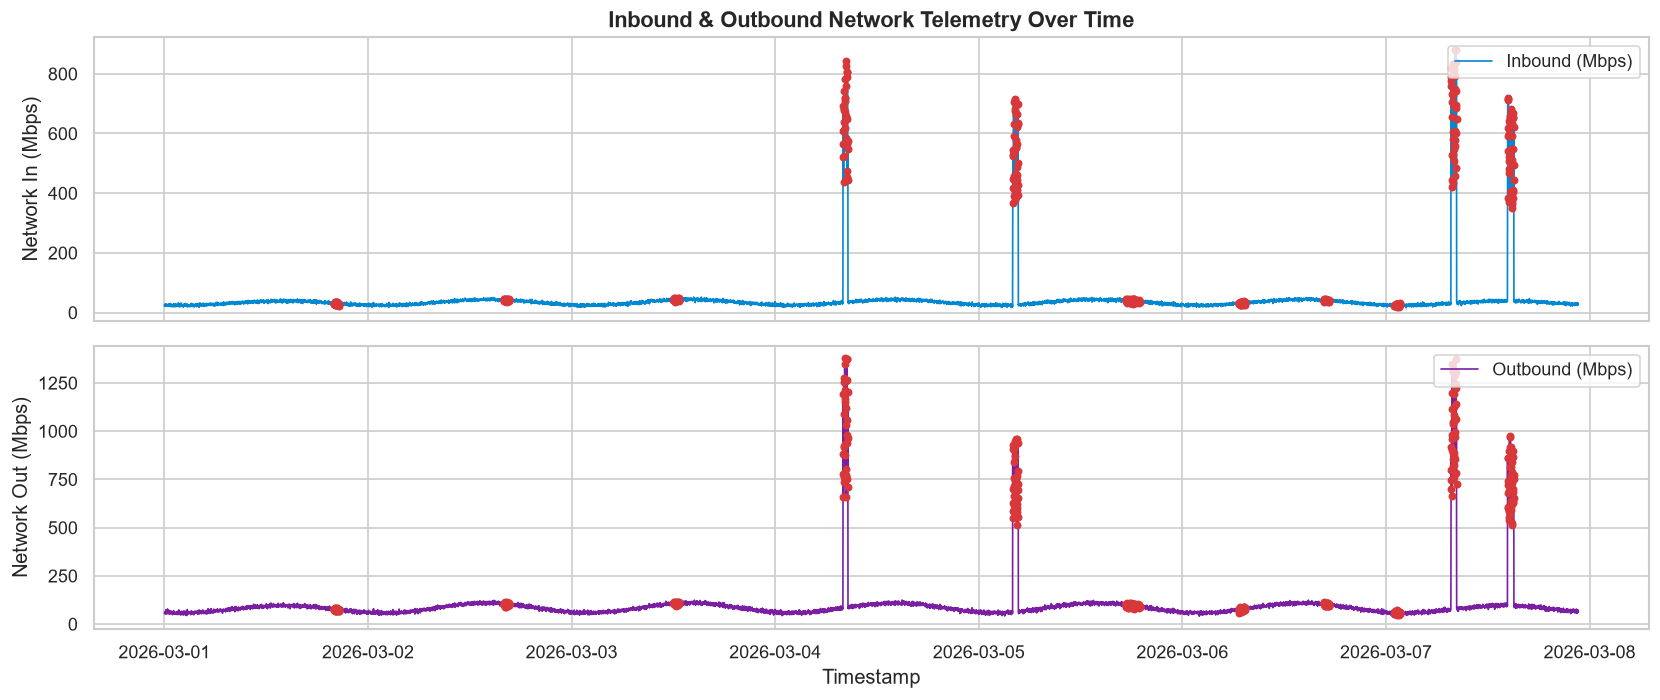

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

ax1.plot(df["timestamp"], df["network_in"], color="#0288d1", label="Inbound (Mbps)", linewidth=1.0)
ax1.scatter(anom["timestamp"], anom["network_in"], color="#d9383a", s=14, zorder=5)
ax1.set_ylabel("Network In (Mbps)")
ax1.legend(loc="upper right")
ax1.set_title("Inbound & Outbound Network Telemetry Over Time", fontsize=13, fontweight="bold")

ax2.plot(df["timestamp"], df["network_out"], color="#7b1fa2", label="Outbound (Mbps)", linewidth=1.0)
ax2.scatter(anom["timestamp"], anom["network_out"], color="#d9383a", s=14, zorder=5)
ax2.set_ylabel("Network Out (Mbps)")
ax2.set_xlabel("Timestamp")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

### 15. Response Time Visualization

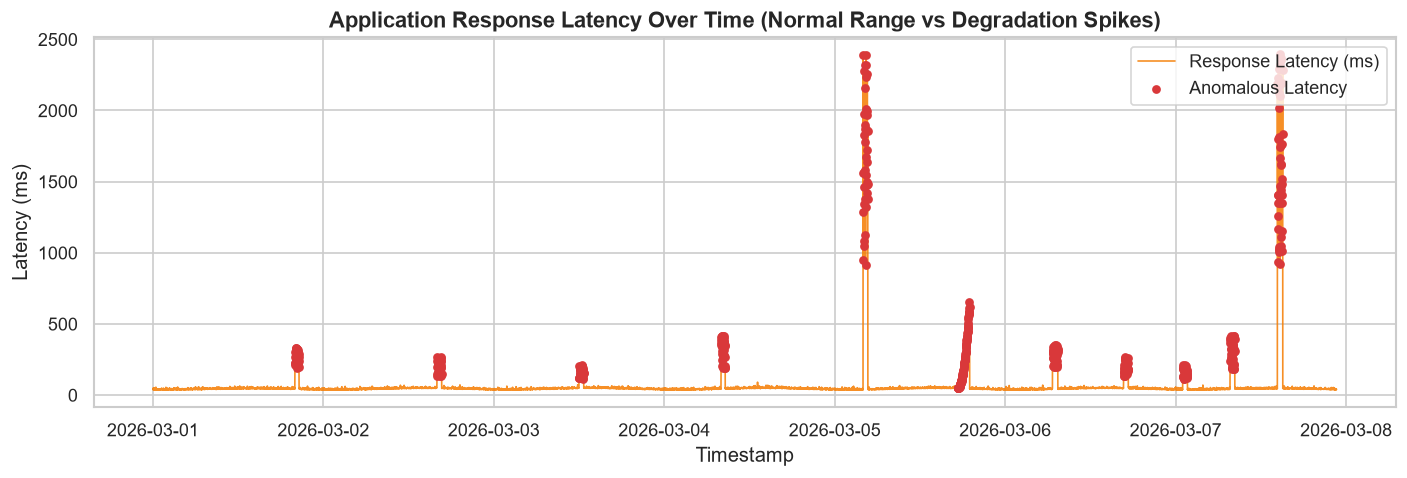

In [13]:
plt.figure(figsize=(14, 4))
plt.plot(df["timestamp"], df["response_time"], color="#f57c00", label="Response Latency (ms)", linewidth=1.0, alpha=0.85)
plt.scatter(anom["timestamp"], anom["response_time"], color="#d9383a", s=18, label="Anomalous Latency", zorder=5)
plt.title("Application Response Latency Over Time (Normal Range vs Degradation Spikes)", fontsize=13, fontweight="bold")
plt.xlabel("Timestamp")
plt.ylabel("Latency (ms)")
plt.legend(loc="upper right")
plt.show()

### 16. Correlation Heatmap

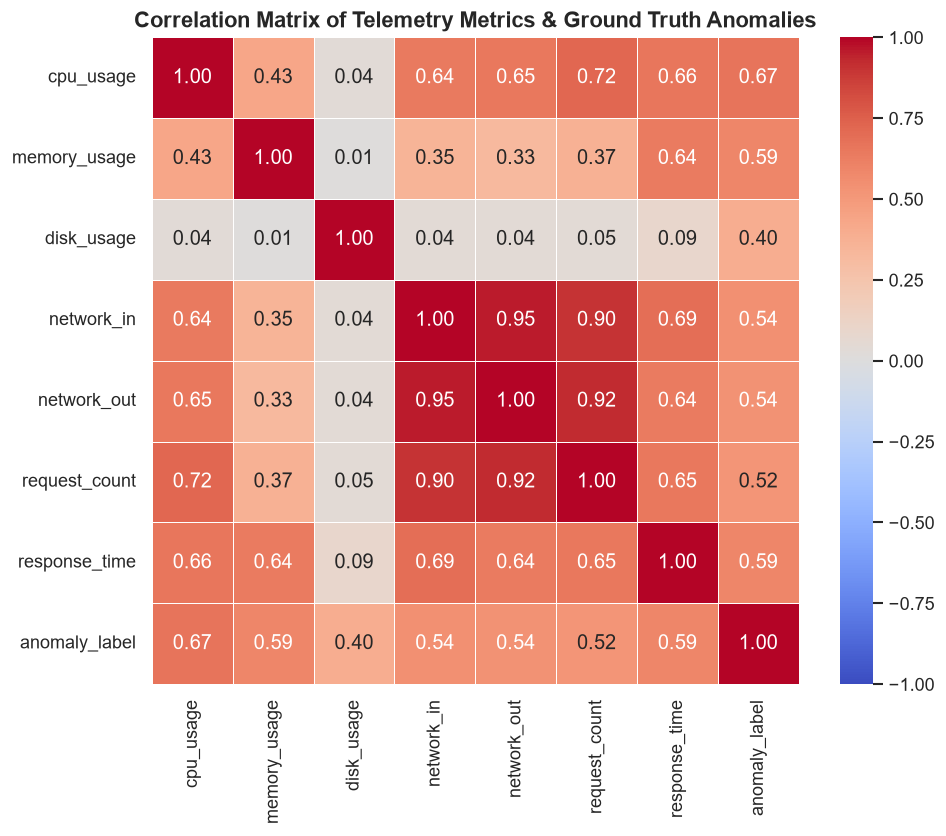

In [14]:
numeric_cols = ["cpu_usage", "memory_usage", "disk_usage", "network_in", "network_out", "request_count", "response_time", "anomaly_label"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1.0, vmax=1.0, square=True, linewidths=0.5)
plt.title("Correlation Matrix of Telemetry Metrics & Ground Truth Anomalies", fontsize=13, fontweight="bold")
plt.show()

### 17. Observations and Conclusions
- **Data Integrity:** Exactly 10,000 observations are recorded across 1-minute steps with zero missing values or duplicate timestamps.
- **Realistic Normal Variability:** Metrics exhibit circadian diurnal fluctuation with realistic cross-feature correlations (requests drive CPU and network; CPU impacts response time).
- **Anomaly Separation:** Anomalies comprise exactly 5.0% (500 records) of the dataset across 6 realistic cloud infrastructure failure patterns.
- **Unsupervised ML Readiness:** While severe anomalies (e.g. combined collapses and extreme CPU spikes) exhibit stark metric deviations, subtle anomalies (such as early-stage gradual degradation) require multi-dimensional correlation, making the dataset an ideal benchmark for the upcoming **Phase 4 Isolation Forest** model.